# Eje 8b — PnL Explanation (atribución por griegas)

Derivados Financieros · QUANt UCEMA

Descomponemos el PnL diario de una opción en contribuciones de **Delta, Gamma, Vega, Theta**
(expansión de Taylor). Lo que no se explica queda como residual (modelo / higher orders / jumps).

> Usamos una serie **sintética** (GBM + precios BS) para que el notebook corra sin pickles legacy.

**Plan**
1. Fórmula de atribución
2. Simular historia spot + opción
3. Calcular PnL mercado vs explained
4. Gráficos
5. Resumen

## 1) Setup

In [1]:
import math
import sys
import timeit
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
for p in [ROOT, *ROOT.parents]:
    if (p / "Codigo" / "pricing").exists():
        sys.path.insert(0, str(p))
        break

print("OK")

OK


In [2]:
from Codigo.pricing import opcion_europea_bs
from Codigo.analytics.gregas_bs import delta_bs, gamma_bs, vega_bs, theta_bs
from Codigo.analytics.vol_implicita import impvolfunc_bs

## 2) Taylor / atribución

$$
\begin{aligned}
\Delta PnL &\approx \Delta\cdot\Delta S + \tfrac12\Gamma (\Delta S)^2
 + \text{Vega}\cdot\Delta\sigma + \Theta\cdot\Delta t + \cdots
\end{aligned}
$$

En la práctica diaria: $\Delta t = 1/252$, $\Delta\sigma$ de la IV, $\Delta S$ del spot.

## 3) Historia sintética

In [3]:
np.random.seed(7)
n_days = 40
dt = 1 / 252
S0, K = 100.0, 100.0
r, div = 0.05, 0.0
# vol "realizada" del spot y vol con la que markeamos la opción
sigma_spot = 0.20
sigma_opt = 0.22  # IV de mark (constante al inicio; luego la perturbamos)

days = np.arange(n_days)
# GBM del spot
z = np.random.normal(size=n_days - 1)
log_ret = (r - 0.5 * sigma_spot**2) * dt + sigma_spot * np.sqrt(dt) * z
S = np.empty(n_days); S[0] = S0
S[1:] = S0 * np.exp(np.cumsum(log_ret))

# IV con un pequeño ruido (sonrisa/dyn)
iv = sigma_opt + 0.01 * np.sin(np.linspace(0, 2*np.pi, n_days)) + 0.005 * np.random.normal(size=n_days)
iv = np.clip(iv, 0.05, 0.60)

T_left = np.maximum(0.25 - days * dt, 1 / 365)  # empieza con ~3m
tipo = "C"
opt_px = np.array([
    opcion_europea_bs(tipo, S[i], K, T_left[i], r, iv[i], div) for i in range(n_days)
])

hist = pd.DataFrame({"S": S, "IV": iv, "tau": T_left, "opt": opt_px})
hist.head()

,S,IV,tau,opt
0,100.000000,0.218353,0.250000,4.975716
1,102.164867,0.225808,0.246032,6.382354
2,101.578982,0.222267,0.242063,5.899619
3,101.633092,0.227488,0.238095,5.985560
4,102.168403,0.222243,0.234127,6.178694


## 4) Atribución día a día

In [4]:
rows = []
for i in range(1, n_days):
    dS = hist.S.iloc[i] - hist.S.iloc[i-1]
    dSig = hist.IV.iloc[i] - hist.IV.iloc[i-1]
    # griegas al inicio del día (t-1)
    s, tau, sig = hist.S.iloc[i-1], hist.tau.iloc[i-1], hist.IV.iloc[i-1]
    dlt = delta_bs(tipo, s, K, tau, r, sig, div)
    gam = gamma_bs(tipo, s, K, tau, r, sig, div)
    veg = vega_bs(tipo, s, K, tau, r, sig, div)
    the = theta_bs(tipo, s, K, tau, r, sig, div)
    pnl_mkt = hist.opt.iloc[i] - hist.opt.iloc[i-1]
    expl = dlt * dS + 0.5 * gam * dS**2 + veg * dSig + the * dt
    rows.append({
        "day": i,
        "PnL_mkt": pnl_mkt,
        "Delta": dlt * dS,
        "Gamma": 0.5 * gam * dS**2,
        "Vega": veg * dSig,
        "Theta": the * dt,
        "PnL_explained": expl,
        "Residual": pnl_mkt - expl,
    })
pnl = pd.DataFrame(rows)
print(pnl[["PnL_mkt", "PnL_explained", "Residual"]].describe().round(6))
pnl.head().round(6)

         PnL_mkt  PnL_explained   Residual
count  39.000000      39.000000  39.000000
mean   -0.096476      -0.095965  -0.000511
std     0.637602       0.640192   0.004252
min    -1.342437      -1.349255  -0.010639
25%    -0.344834      -0.346509  -0.001324
50%    -0.186329      -0.185158   0.000031
75%     0.283242       0.282864   0.000936
max     1.581300       1.591939   0.012851


,day,PnL_mkt,Delta,Gamma,Vega,Theta,PnL_explained,Residual
0,1,1.406638,1.227770,0.084412,0.146592,-0.044342,1.414432,-0.007794
1,2,-0.482735,-0.374659,0.005614,-0.067167,-0.046238,-0.482449,-0.000285
2,3,0.085941,0.033613,0.000050,0.099251,-0.045984,0.086929,-0.000988
3,4,0.193134,0.332545,0.004831,-0.098928,-0.047100,0.191348,0.001786
4,5,-0.736545,-0.640360,0.016950,-0.065993,-0.046563,-0.735967,-0.000578


## 5) Gráficos

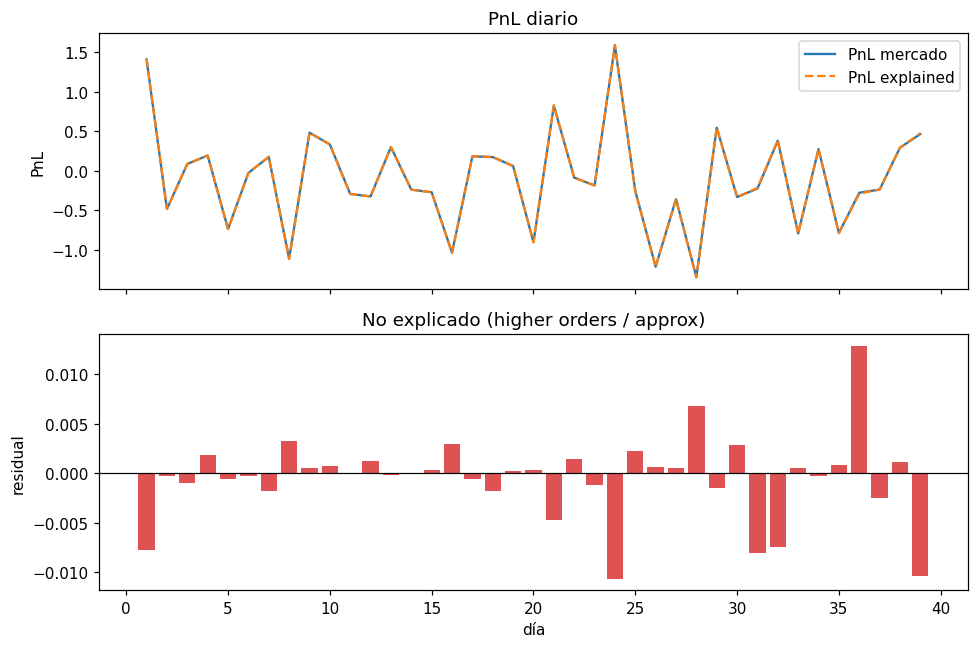

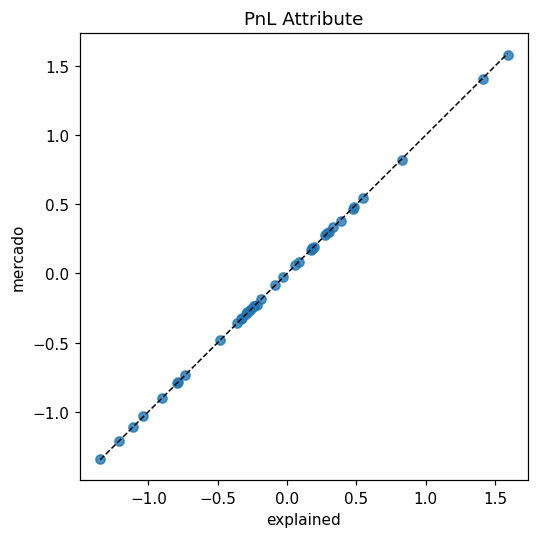

contribución media |·|:
Delta    0.499254
Gamma    0.040054
Vega     0.091148
Theta    0.048787
dtype: float64


In [5]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), dpi=110, sharex=True)
axes[0].plot(pnl["day"], pnl["PnL_mkt"], label="PnL mercado")
axes[0].plot(pnl["day"], pnl["PnL_explained"], "--", label="PnL explained")
axes[0].legend(); axes[0].set_ylabel("PnL"); axes[0].set_title("PnL diario")
axes[1].bar(pnl["day"], pnl["Residual"], color="C3", alpha=0.8)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xlabel("día"); axes[1].set_ylabel("residual")
axes[1].set_title("No explicado (higher orders / approx)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(5, 5), dpi=110)
ax.scatter(pnl["PnL_explained"], pnl["PnL_mkt"], alpha=0.8)
lims = [
    min(pnl["PnL_mkt"].min(), pnl["PnL_explained"].min()),
    max(pnl["PnL_mkt"].max(), pnl["PnL_explained"].max()),
]
ax.plot(lims, lims, "k--", lw=1)
ax.set_xlabel("explained"); ax.set_ylabel("mercado")
ax.set_title("PnL Attribute")
plt.tight_layout(); plt.show()

# contribución media abs
contrib = pnl[["Delta", "Gamma", "Vega", "Theta"]].abs().mean()
print("contribución media |·|:")
print(contrib.round(6))

## Resumen

- PnL explanation ≈ control de modelo: si el residual es sistemático, el mark (IV/modelo) falla.
- Delta+Gamma capturan movimiento del spot; Vega la IV; Theta el paso del tiempo.
- En datos reales (BYMA/US) el flujo es el mismo: serie de spot, mid de opción, IV, griegas, residual.

**Ejercicio:** poné `sigma_opt` distinto de `sigma_spot` y mirá si crece el residual medio.

**Siguiente:** **09a** — volatilidad implícita.